"Can an MLP classify fetal health from CTG features, and how well does it detect Pathological cases?"

In [60]:
import os
import pandas as pd
from google.colab import drive

# Mounting Google Drive
drive.mount('/content/drive', force_remount=True)

# Searching for the file in Google Drive
target_file = 'fetal_health.xls'
file_path = None

for root, dirs, files in os.walk('/content/drive/My Drive'):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        print(f"Found file at: {file_path}")
        break

if file_path:
    # Install xlrd for old Excel formats (.xls) like girl what why would we have an old formatt
    !pip install -q xlrd

    try:
        print("Attempting to read with xlrd engine...")
        df = pd.read_excel(file_path, engine='xlrd')
        print("Successfully loaded using Excel engine!")
    except Exception as e:
        print(f"Excel read failed: {e}. Attempting to read as a CSV file...")
        try:
            # It's actually a TSV/CSV files because why wouldn't it be
            df = pd.read_csv(file_path, sep=None, engine='python')
            print("Successfully loaded as text/CSV!")
        except Exception as csv_err:
            raise RuntimeError("Failed to parse the file as Excel or CSV.") from csv_err

    print("Dataset Shape:", df.shape)
    display(df.head())
else:
    print(f"Could not find '{target_file}' in your Google Drive.")

Mounted at /content/drive
Found file at: /content/drive/My Drive/FALL26/INFO4604 - Applied Machine Learning/2PortfolioProject/fetal_health.xls
Attempting to read with xlrd engine...
Excel read failed: Unsupported format, or corrupt file: Expected BOF record; found b'baseline'. Attempting to read as a CSV file...
Successfully loaded as text/CSV!
Dataset Shape: (2126, 22)


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [61]:
df.head()
df.shape
df.info()          # column types + non-null counts
df.describe()
df.isnull().sum()  # how much is missing, per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability  

,0
baseline value,0
accelerations,0
fetal_movement,0
uterine_contractions,0
light_decelerations,0
severe_decelerations,0
prolongued_decelerations,0
abnormal_short_term_variability,0
mean_value_of_short_term_variability,0
percentage_of_time_with_abnormal_long_term_variability,0


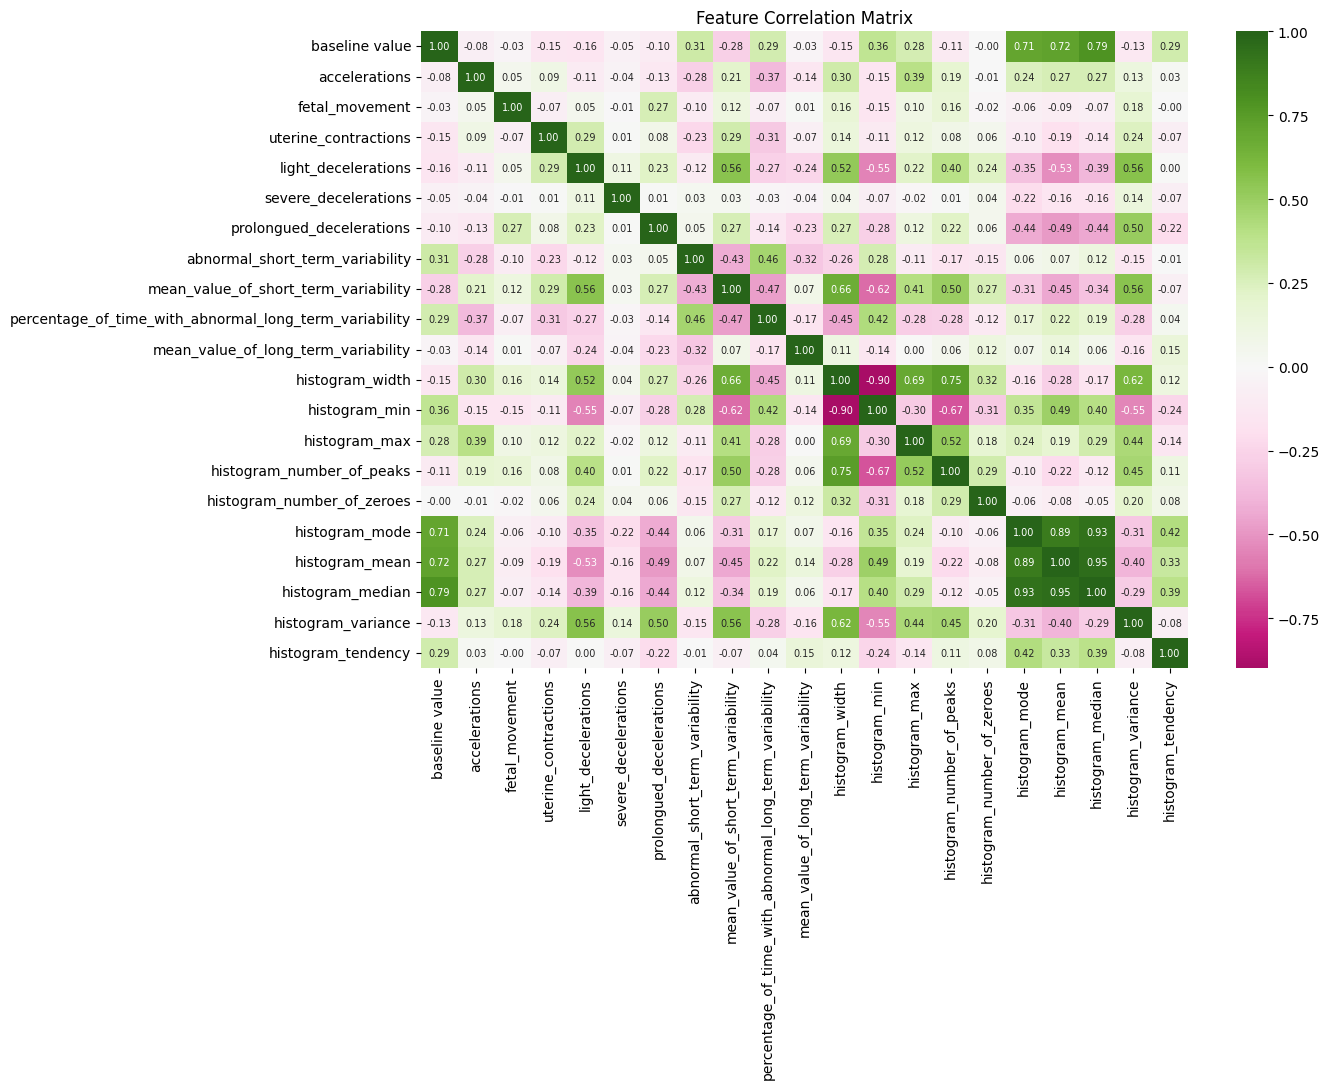

histogram_mean  histogram_median    0.948251
histogram_mode  histogram_median    0.933399
dtype: float64


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation heatmap (features only, target excluded)
features = df.drop(columns='fetal_health')
corr = features.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='PiYG', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

# the highly correlated pairs
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack().loc[lambda s: s.abs() > 0.9].sort_values(ascending=False)
print(high_pairs)

A cardiotocogram (CTG) records the baby's heart rate and the mother's contractions during pregnancy or labour. Clinicians read the trace and sort it into one of three categories:

Normal (1): a reassuring trace. The heart rate and its variability look healthy, and no action is needed beyond routine monitoring.
Suspect (2): some features are borderline or not fully reassuring. It isn't clearly dangerous, but the baby needs closer monitoring and possibly more tests.
Pathological (3): an abnormal trace that suggests the baby may not be getting enough oxygen. This usually calls for urgent action, such as further assessment or a faster delivery.

In [63]:
# Class balance

counts = df['fetal_health'].value_counts().sort_index()
percent = (counts / len(df) * 100).round(1)
print(pd.DataFrame({'count': counts, 'percent': percent},
                   index=[1.0, 2.0, 3.0]).rename(index={1.0: 'Normal', 2.0: 'Suspect', 3.0: 'Pathological'}))

              count  percent
Normal         1655     77.8
Suspect         295     13.9
Pathological    176      8.3


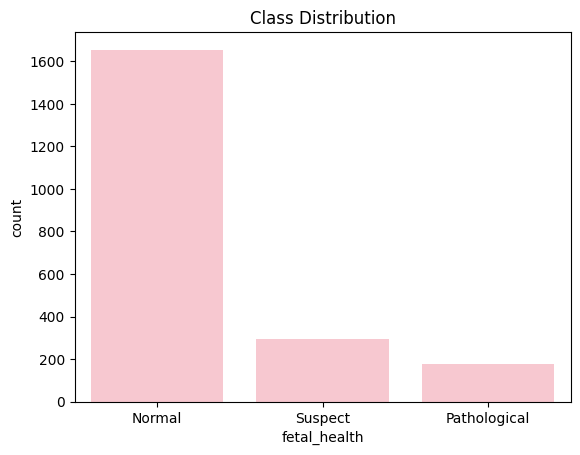

In [64]:
# Bar chart

sns.countplot(x='fetal_health', data=df, color='pink')
plt.xticks([0, 1, 2], ['Normal', 'Suspect', 'Pathological'])
plt.title('Class Distribution')
plt.show()

In [66]:
# split and scale the data

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features and target (classes 1,2,3 -> 0,1,2)
X = df.drop(columns='fetal_health').values
y = df['fetal_health'].astype(int).values - 1

# Split: 70% train, then the remaining 30% split equally into validation and test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

In [67]:
# fit on training data ONLY, then apply to all three sets
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train) # learn min/max from training data only
X_val   = scaler.transform(X_val) # apply the same min/max
X_test  = scaler.transform(X_test)

# Check the results
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
for name, labels in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    print(name, np.bincount(labels))

Train: (1488, 21) Val: (319, 21) Test: (319, 21)
Train [1158  207  123]
Val [248  44  27]
Test [249  44  26]


In [68]:
# train the MLP

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

In [69]:
from sklearn.utils.class_weight import compute_class_weight

cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(cw))
print(class_weights)

{0: np.float64(0.4283246977547496), 1: np.float64(2.396135265700483), 2: np.float64(4.032520325203252)}


In [70]:
# model 1

model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Dense(64, activation='relu', input_shape=(21,)))
# add a dropout layer
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(64, activation='relu'))
model.add(tf.keras.layers.Dense(3, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [71]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,763 (22.51 KB)

 Trainable params: 5,763 (22.51 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
# we have to do this model.complie to pre compile it before we train it
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# 10 epochs is probably too few for a dataset this small
model.fit(X_train, y_train, epochs=75, class_weight=class_weights)

Epoch 1/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5961 - loss: 1.0211
Epoch 2/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7386 - loss: 0.8541
Epoch 3/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7500 - loss: 0.7183
Epoch 4/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7728 - loss: 0.6267
Epoch 5/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7964 - loss: 0.5753
Epoch 6/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7984 - loss: 0.5419
Epoch 7/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8159 - loss: 0.5061
Epoch 8/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8118 - loss: 0.4924
Epoch 9/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8165 - loss: 0.4809
Epoch 10/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8118 - loss: 0.4651
Epoch 11/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8347 - loss: 0.4424
Epoch 12/75
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8239 - lo

In [ ]:
model_loss, model_accuracy = model.evaluate(X_test, y_test, verbose=2)
print(f"Loss: {model_loss}, Accuracy: {model_accuracy}")

In [ ]:
# print confusion matrix
# the confusion matrix shows why accuracy isn't the whole story
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

# Get predicted class probabilities
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=1)

y_test_labels = y_test

# The confusion matrix is useful,
# but the research question is about catching at-risk cases
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_labels,
                            target_names=['Normal', 'Suspect', 'Pathological']))

print("Confusion Matrix:")
print(confusion_matrix(y_test_labels, y_pred_labels))